<a href="https://colab.research.google.com/github/oooinr4018-web/-1/blob/main/ESAA_1116_%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7.5. LSTM

RNN: 기울기가 1보다 작은 값이 계속 곱해짐 -> 기울기 소멸 문제

해결 방법: LSTM, 확장된 RNN

# 7.5.1. LSTM 구조

LSTM: 망각 게이트, 입력 게이트,출력 게이트를 각 뉴런에 추가 (기울기 소멸 문제 해결)

- 망각 게이트

: 과거 정보를 어느 정도 기억할지 결정

: 입력값 - 과거 정보, 현재 데이터 -> 시그모이드 취하기 -> 그 값을 과거 정보에 곱해주기

: 출력값 = 0 : 과거 정보 버리기
         = 1 : 과거 정보 보존

: h(t-1): 이전 은닉층에서 입력되는 값, x(i): 새로운 입력 값

-> 이전 상태를 현재 메모리에 반영할지 결정하는 역할

- 입력 게이트

: 현재 정보를 기억하기 위해 만들어짐.

: 입력값 - 과거 정보, 현재 데이터 -> 시그모이드, 하이퍼볼릭 탄젠트 함수 -> 현재 정보 보존량 결정

-> 현재 메모리에 새로운 정보 반영할지 결정


- 메모리 셀

: 각 단계에 대한 은닉 노드

: 총합 -> 셀 값 반영 -> 기울기 소멸 문제 해결

: 망각 게이트, 입력 게이트의 이전 단계 셀 정보 계산 -> 현재 단계의 셀 상태 업데이트


- 출력 게이트

: 갱신된 메모리의 출력 값을 제어하는 역할

(계산 값 = 1 -> 의미 있는 결과로 최종 출력

계산 값 = 0 -> 해당 연산 출력 X)

: 과거 정보, 현재 데이터 사용하여 뉴런의 출력 결정

: 이전 은닉 상태, t번째 입력 -> 다음 은닉 상태

: LSTM에서 은닉 상태 = 그 시점에서의 출력







LSTM 역전파

LSTM: 셀을 통해서 역전파 수행 -> 중단 없는 기울기

최종 오차는 모든 노드에 전파 (셀을 통해 중단 없이 전파)

: 셀 내부적으로 오차가 입력으로 전파



# 7.5.2. LSTM 셀 구현

데이터셋: MNIST (손으로 쓴 숫자 이미지들로 구성)



In [48]:
# 코드 7-29, 라이브러리 호출

import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.nn import Parameter # 파라미터 목록을 갖고 있는 라이브러리
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math # 수학 관련 다양한 함수, 상수 정의되어 있는 라이브러리

device=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda=True if torch.cuda.is_available() else False # GPU 사용에 필요

Tensor=torch.cuda.FloatTensor if cuda else torch.FloatTensor # GPU 사용에 필요

torch.manual_seed(125)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(125)

In [49]:
# 코드 7-30. 데이터 전처리

import torchvision.transforms as transforms

mnist_transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (1.0,)) # 평균 0.5, 표준편차 1.0으로 데이터 정규화
])

In [50]:
# 코드 7-31. 데이터셋 내려받기

from torchvision.datasets import MNIST

download_root='../chap07/MNIST_DATASET'
train_dataset=MNIST(download_root, transform=mnist_transform, train=True, download=True)
valid_dataset=MNIST(download_root, transform=mnist_transform, train=False, download=True)
test_dataset=MNIST(download_root, transform=mnist_transform, train=False, download=True)



- 첫 번째 파라미터: MNIST 내려받을 위치 지정

- transform: 데이터 전처리 적용

- train: True면 훈련용 데이터셋 가져오기, False면 테스트용 데이터셋 가져오기

- download: True일 경우, MNIST 파일이 없으면 내려받기, 파일이 있다면 내려받지 않기

In [51]:
# 코드 7-32. 데이터셋을 메모리로 가져오기

batch_size=64
train_loader=DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
valod_loader=DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)
test_loader=DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

In [52]:
# 코드 7-33. 변수 값 지정
batch_size=100
n_iters=6000
num_epochs=n_iters/(len(train_dataset)/batch_size)
num_epochs=int(num_epochs)

- LSTM 셀에 대한 네트워크 구축 (모델의 전반적인 네트워크 X)


In [53]:
# 코드 7-34. LSTM 셀 네트워크 구축

class LSTMCell(nn.Module):
  def __init__(self, input_size, hidden_size, bias=True):
    super(LSTMCell, self).__init__()
    self.input_size=input_size
    self.hidden_size=hidden_size
    self.bias=bias
    self.x2h=nn.Linear(input_size, 4*hidden_size, bias=bias)
    self.h2h=nn.Linear(hidden_size, 4*hidden_size, bias=bias)
    self.reset_parameters()

  def reset_parameters(self):
    std=1.0 / math.sqrt(self.hidden_size)
    for w in self.parameters():
      w.data.uniform_(-std,std)

  def forward(self, x, hidden):
    hx, cx=hidden
    x=x.view(-1, x.size(1))

    gates=self.x2h(x)+self.h2h(hx)
    ingate, forgetgate, cellgate, outgate=gates.chunk(4, 1)

    ingate=F.sigmoid(ingate)
    forgetgate=F.sigmoid(forgetgate)
    cellgate=F.tanh(cellgate)
    outgate=F.sigmoid(outgate)

    cy=torch.mul(cx, forgetgate)+torch.mul(ingate, cellgate)
    hy=torch.mul(outgate, F.tanh(cy))
    return(hy, cy)

- self.x2h, self.h2h에서 인자로 4*hidden_size가 사용됨.

-> 은닉층의 뉴런/유닛에 4를 곱하는 이유

: gates.chunk(4,1)에 의해 네 개로 쪼개져서 각각 망각, 입력, 셀, 출력 게이트를 의미하는 변수에 저장

(gates가 4개로 쪼개지는 상황이어서 4가 곱해짐.)

(일반적으로 바이어스에도 4를 곱해줌.)

- torch.chunk: 텐서를 쪼갤 때 사용하는 함수

torch.chunk(4,1)

첫 번째 파라미터: 텐서를 몇 개로 쪼갤지 결정

두 번째 파라미터: 어떤 차원을 기준으로 쪼갤지 결정

(dim = 1 : 열 단위로 텐서 분할)

- uniform(): 난수를 위해 사용

(난수 사용: randint(), random() 등)

randint(1,10): 1~10 사이의 정수

random(): 0~1 사이의 임의의 실수

unifrom(1,10): 1~10 사이의 임의의 실수

randrange(1, 10, 2): 1~10 사이를 2씩 건너뛴 임의의 정수

- torch.squeeze(): 텐서의 차원 줄이기

x.squeeze(): squeeze() 적용 -> 1차원으로 축소

torch.FloatTensor([[1], [2]]): (2x1) 크기의 2차원 텐서 생성

하나의 LSTM 셀 통과 -> 출력: 셀(ci), 은닉(hi)

셀 상태: 입력, 망각, 셀 게이트에 의해 계산

은닉 상태: 출력 게이트에 의해 계산

- torch.mul(): 텐서에 곱셈에 사용

torch.mul(x, 3): x 텐서의 원소에 3 곱하기











In [54]:
# 코드 7-35. LSTM 셀의 전반적인 네트워크
class LSTMModel(nn.Module):
  def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
    super(LSTMModel, self).__init__()
    self.hidden_dim=hidden_dim # 은닉층의 누란/유닛 개수

    self.layer_dim=layer_dim
    self.lstm=LSTMCell(input_dim, hidden_dim, layer_dim)
    self.fc=nn.Linear(hidden_dim, output_dim)

  def forward(self, x):
    if torch.cuda.is_available():
      h0=Variable(torch.zeros(self.layer_dim, x.size(0), self,hidden_dim).cuda())
    else:
      h0=Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))
    if torch.cuda.is_available():
      c0=Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
    else:
      c0=Variable(torch.zeros(self.layer_dim, x.size(0), hidden_dim))

    outs=[]
    cn=c0[0,:,:]
    hn=h0[0,:,:]

    for seq in range(x.size(1)):
      hn, cn=self.lstm(x[:,seq,:], (hn,cn))
      outs.append(hn)

      out=outs[-1].squeeze()
      out=self.fc(out)
      return out



- LSTM 셀: 앞에서 정의한 함수 불러오는 부분

파라미터: input_dim, hidden_dum, layer_dim

input_dim: 입력 특성 수

hidden_dim: 은닉층의 뉴런 개수

layer_dim: 은닉층의 계층 개수



In [55]:
# 코드 7-36. 옵티마이저, 손실 함수 지정
input_dim=28
hidden_dim=128
layer_dim=1
output_dim=10

model=LSTMModel(input_dim, hidden_dim, layer_dim, output_dim)
if torch.cuda.is_available():
  model.cuda()
criterion=nn.CrossEntropyLoss()
learning_rate=0.1
optimizer=torch.optim.SGD(model.parameters(), lr=learning_rate)

In [56]:
# 코드 7-37. 모델 학습 및 성능 확인
# 훈련 데이터셋으로 모델 학습
# 검증 데이터셋으로 모델 성능 확인

seq_dim=28
loss_list=[]
iter=0
for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader):
    if torch.cuda.is_available():
      images=Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels=Variable(labels.cuda())
    else:
      images=Variable(images.view(-1, seq_dim, input_dim))
      labels=Variable(labels)

    optimizer.zero_grad()
    outputs=model(images)
    loss=criterion(outputs, labels)

    if torch.cuda.is_available():
      loss.cuda()

    loss.backward()
    optimizer.step()
    loss_list.append(loss.item())
    iter+=1

    if iter%500==0:
      correct=0
      total=0
      for images, labels in test_loader:

        if torch.cuda.is_available():
          images=Variable(images.view(-1, seq_dim, input_dim).cuda())
        else:
          images=Variable(images.view(-1, seq_dim, input_dim))

- 정확도가 97%

In [66]:
# 코드 7-38. 테스트 데이터셋을 이용한 모델 예측 성능 확인
# 테스트 데이터셋으로 모델 예측 성능 살펴보기

def evaluate(model, val_iter):
  corrects, total, total_loss=0,0,0
  model.eval()
  for images, labels in val_iter:
    if torch.cuda.is_available():
      images=Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels=labels.cuda()
    else:
      images=Variable(images.view(-1, seq_dim, input_dim)).to(device)
      labels=labels.to(device)

      logit=model(images).to(device)
      loss=F.cross_entropy(logit, labels, reduction="sum")
      _, predicted=torch.max(logit.data, 1)
      total+=labels.size(0)
      total_loss+=loss.item()
      corrects+=(predicted==labels).sum()

      avg_loss=total_loss/len(val_iter.dataset)
      avg_accuracy=corrects/total
      return avg_loss, avg_accuracy

- 모델 학습, 모델 예측 코드 비슷한 패턴으로 진행

- 파라미터에 집중

In [67]:
# 코드 7-39, 모델 예측 성능 확인
test_loss, test_acc=evaluate(model, test_loader)
print("Test Loss: %5.2f | Test Accuracy: %5.2f" % (test_loss, test_acc))

Test Loss:  0.01 | Test Accuracy:  0.05


- IMDB: 사전에 전처리가 되지 않은 데이터셋

- MNIST: 사전에 전처리가 된 데이터셋

- 사전에 전처리가 되지 않은 데이터셋의 경우, 정확도를 높이기 위해 은닉층의 개수, 하이퍼파라미터 수정 등이 필요함.


# 7.5.3. LSTM 계층 구현

- 데이터셋: 스타벅스 주가 데이터셋

In [68]:
# 코드 7-40, 라이브러리 호출

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')


In [75]:
!pip install -q yfinance

In [76]:
# 데이터셋 가져오기
import pandas as pd
import yfinance as yf

data = yf.download(
    "SBUX",
    start="2015-01-01",
    end="2026-11-16",
    auto_adjust=False,
    progress=False
)

data.columns = data.columns.get_level_values(0)
data = data.reset_index()

data.to_csv("SBUX.csv", index=False)

print(data.dtypes)
print(data.head())

Price
Date         datetime64[ns]
Adj Close           float64
Close               float64
High                float64
Low                 float64
Open                float64
Volume                int64
dtype: object
Price       Date  Adj Close      Close       High        Low       Open  \
0     2015-01-02  31.888325  40.720001  41.490002  40.445000  41.064999   
1     2015-01-05  31.277496  39.939999  40.334999  39.744999  40.070000   
2     2015-01-06  31.022991  39.615002  40.195000  39.279999  40.169998   
3     2015-01-07  31.786526  40.590000  40.615002  39.700001  39.875000   
4     2015-01-08  32.299454  41.244999  41.650002  41.009998  41.165001   

Price    Volume  
0       6886000  
1      11623800  
2       7664400  
3       9732600  
4      13170600  


In [77]:
# 코드 7-41. 데이터셋 가져오기
data = pd.read_csv("SBUX.csv")
print(data.dtypes)

Date          object
Adj Close    float64
Close        float64
High         float64
Low          float64
Open         float64
Volume         int64
dtype: object


- 데이터셋의 'Date' 칼럼을 인덱스로 사용

- 단어들로 구성된 데이터셋의 임베딩 과정 필요



In [78]:
# 코드 7-42. 날짜 칼럼을 인덱스로 사용
data['Date']=pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)

In [80]:
# 코드 7-43. 데이터 형식 변경
data['Volume']=data['Volume'].astype(float)

In [81]:
# 코드 7-44. 훈련과 레이블 분리

X=data.iloc[:, :-1]
y=data.iloc[:, 5:6]
print(X)
print(y)

             Adj Close       Close        High         Low        Open
Date                                                                  
2015-01-02   31.888325   40.720001   41.490002   40.445000   41.064999
2015-01-05   31.277496   39.939999   40.334999   39.744999   40.070000
2015-01-06   31.022991   39.615002   40.195000   39.279999   40.169998
2015-01-07   31.786526   40.590000   40.615002   39.700001   39.875000
2015-01-08   32.299454   41.244999   41.650002   41.009998   41.165001
...                ...         ...         ...         ...         ...
2026-11-09  108.797203  109.440002  110.190002  106.279999  106.309998
2026-11-10  109.304199  109.949997  109.980003  107.349998  108.769997
2026-11-11  109.244553  109.889999  110.300003  108.629997  109.889999
2026-11-12  106.630005  107.260002  110.550003  107.180000  109.489998
2026-11-13  106.440002  106.440002  107.610001  106.320000  106.650002

[2985 rows x 5 columns]
                Volume
Date                  
2015-0

- 데이터 간의 분포가 다르게 나타남. -> 분포를 고르게 맞추기 위한 과정 필요 (MinMaxScaler(), StandardScaler()로 분산 조정)



In [83]:
# 코드 7-45. 데이터 분포 조정
ms=MinMaxScaler()
ss=StandardScaler()

X_ss=ss.fit_transform(X)
y_ms=ms.fit_transform(y)

X_train=X_ss[:200, :]
X_test=X_ss[200:, :]

y_train=y_ms[:200, :]
y_test=y_ms[200:, :]

print("Training Shape", X_train.shape, y_train.shape)
print("Test Shape", X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Test Shape (2785, 5) (2785, 1)


In [84]:
# 코드 7-46. 데이터셋의 형태 및 크기 조정
X_train_tensors=Variable(torch.Tensor(X_train))
X_test_tensors=Variable(torch.Tensor(X_test))

y_train_tensors=Variable(torch.Tensor(y_train))
y_test_tensors=Variable(torch.Tensor(y_test))

X_train_tensors_f=torch.reshape(X_train_tensors, (X_train_tensors.shape[0],
                                                   1, X_train_tensors.shape[1]))
X_test_tensors_f=torch.reshape(X_test_tensors, (X_test_tensors.shape[0],
                                                1, X_test_tensors.shape[1]))
print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("Testing Shape", X_test_tensors_f.shape, y_test_tensors.shape)


Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Testing Shape torch.Size([2785, 1, 5]) torch.Size([2785, 1])


- torch.reshape: 텐서 형태 변환

(LSTM 네트워크의 입력 형태와 맞추기 위해서)

In [85]:
# 코드 7-47. LSTM 네트워크
class LSTM(nn.Module):
  def __init__(self, num_cloasses, input_size, hidden_size, num_layers, seq_length):
    super(LSTM, self).__init__()
    self.num_classes=num_classes
    self.num_layers=num_layers
    self.input_size=input_size
    self.hidden_size=hidden_size
    self.seq_length=seq_length

    self.lstm=nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                      num_layers=num_layers, batch_first=True)
    self.fc_1=nn.Linear(hidden_size, 128)
    self.fc=nn.Linear(128, num_classes)
    self.relu=nn.ReLU()
  def forward(self,x):
    h_0=Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size))
    c_0=Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size))
    output, (hn, cn)=self.lstm(x, (h_0, c_0))
    hn=hn.view(-1, self.hidden_size)
    out=self.relu(hn)
    out=self.fc_1(out)
    out=self.relu(out)
    out=self.fc(out)
    return out


In [86]:
# 코드 7-48. 변수 값 설정

num_epochs=1000
learning_rate=0.0001

input_size=5
hidden_size=2
num_layers=1

num_classes=1
model=LSTM(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1])

criterion=torch.nn.MSELoss()
optimizer=torch.optim.Adam(model.parameters(), lr=learning_rate)

In [88]:
# 코드 7-49. 모델 학습
for epoch in range(num_epochs):
  outputs=model.forward(X_train_tensors_f)
  optimizer.zero_grad()
  loss=criterion(outputs, y_train_tensors)
  loss.backward()

  optimizer.step()
  if epoch%100==0:
    print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.11038
Epoch: 100, loss: 0.01009
Epoch: 200, loss: 0.00090
Epoch: 300, loss: 0.00074
Epoch: 400, loss: 0.00074
Epoch: 500, loss: 0.00074
Epoch: 600, loss: 0.00074
Epoch: 700, loss: 0.00074
Epoch: 800, loss: 0.00074
Epoch: 900, loss: 0.00074


- 오차 위주로 출력 -> 실제로 얼마나 잘 예측했는지 알기 어려움.



In [89]:
# 코드 7-50, 모델 예측 결과를 출력하기 위한 데이터 크기 재구성
# 예측 결과 시각적으로 표현
# 레이블, 예측 결과 출력을 위한 전처리 진행

df_x_ss=ss.transform(data.iloc[:, :-1])
df_y_ms=ms.transform(data.iloc[:, -1:])

df_x_ss=Variable(torch.Tensor(df_x_ss))
df_y_ms=Variable(torch.Tensor(df_y_ms))
df_x_ss=torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

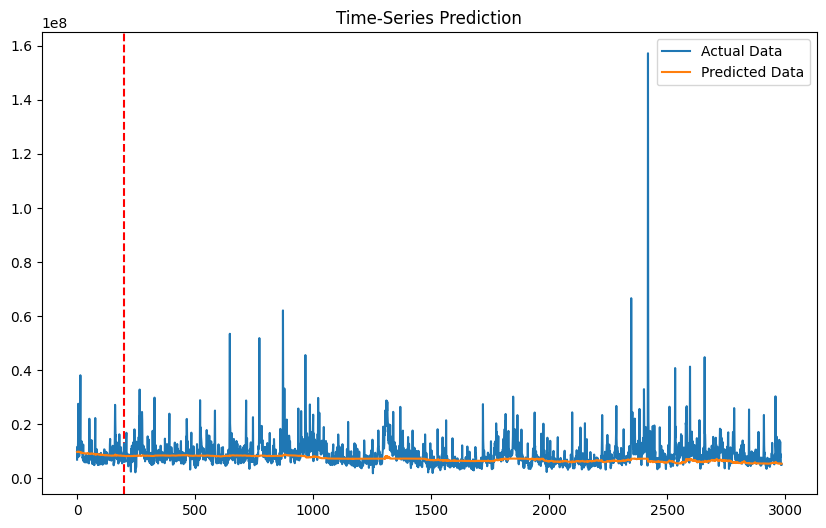

In [91]:
# 코드 7-51. 모델 예측 결과 출력
train_predict=model(df_x_ss)
predicted=train_predict.data.numpy()
label_y=df_y_ms.data.numpy()

predicted=ms.inverse_transform(predicted)
label_y=ms.inverse_transform(label_y)
plt.figure(figsize=(10,6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()

- axvline(): 그래프의 축을 따라 수직선 표현

plt.axvline(x=200, c='r', linestyle='--')

수평선은 axhline

첫 번째 파라미터: 어떤 지점에 수직선 표현할지 지정

c: 어떤 색상으로 수직선 표현할지 지정

linestyle: 어떤 스타일로 수직선 표현할지 지정

- 파란색: 실제 레이블 출력 결과

- 주황색: 모델이 예측한 결과

결과가 만족스럽지 않음 -> 하이퍼파라미터에 대한 튜닝, 모델 변경

